# Modelos finales, prueba fuera de muestra 2025 y pronóstico

Este notebook deja los modelos listos para usar:

1. **Modelos finales.** Un XGBoost por departamento y horizonte (1 a 4 semanas), sin clima y con clima, entrenado con **todos los datos de 2010–2024** y la configuración que eligió la validación del notebook 09. Se guardan en `modelos/`, que git ignora, junto con un archivo de metadatos.
2. **Prueba real fuera de muestra: 2025.** El CSV del CDC trae los casos de 2025, que ningún modelo vio. Se pronostica 2025 semana a semana con los modelos entrenados hasta 2024 y se compara con lo que realmente pasó.
3. **Pronóstico** para las 4 semanas siguientes al último dato disponible (semana 53 de 2025), es decir, las semanas 1 a 4 de 2026.
4. **Datos del tablero.** Junta todo en `data/processed/tablero.parquet` para `app/tablero.py`.

**Modelo de producción: XGBoost sin clima.** Tiene dos razones:
- El notebook 11 mostró que el clima no mejora el pronóstico de forma robusta.
- La tabla de clima termina en 2024, así que un modelo que necesita clima no puede pronosticar 2025.

El modelo con clima igual se guarda, para cuando haya clima actualizado.

**Nota:** los casos de 2025 son provisionales. El CDC advierte que sus datos pueden actualizarse.

## Configuración

In [1]:
# Rutas: el notebook funciona desde la raiz del proyecto o desde notebooks/
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))

In [2]:
import datetime as dt
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from epiweeks import Week

from comun import HORIZONTES, REGIONES, fecha_central
from modelado import (N_REZAGOS, CATEGORIAS, ICEN, a_casos, candidatas, departamentos_modelables,
                      marcar_brotes, metricas, modelo_xgb, preparar_panel, seleccionar, umbral_brote,
                      objetivo_de)

PROC, INTERIM, OUT, RAW = (ROOT / "data" / "processed", ROOT / "data" / "interim", ROOT / "outputs",
                           ROOT / "data" / "raw")
MODELOS = ROOT / "modelos"
MODELOS.mkdir(exist_ok=True)
SIN_CLIMA, CON_CLIMA = "XGBoost sin clima", "XGBoost con clima"
ULTIMO_ANO_ENTRENAMIENTO = 2024
CSV_2025 = RAW / "datos_abiertos_vigilancia_dengue_2000_2025.csv"

AZUL, NARANJA, AQUA, TINTA, TINTA_2, REJ = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#e1e0d9"


def estilo(ax):
    ax.grid(color=REJ, lw=0.6)
    ax.set_axisbelow(True)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)

## 1. Modelos finales (2010–2024)

La configuración de cada departamento y horizonte (objetivo, profundidad, `min_child_weight` y número de árboles) sale de la validación del notebook 09 (`outputs/fase3_metricas.csv`). Para el modelo con clima, las variables climáticas se vuelven a seleccionar con todos los años.

In [3]:
panel_depto = pd.read_parquet(PROC / "panel_depto_semana.parquet")
panel = preparar_panel(panel_depto)
deptos, _ = departamentos_modelables(panel)
config_09 = pd.read_csv(OUT / "fase3_metricas.csv")
config_09 = config_09[(config_09["conjunto"] == "Prueba") & config_09["modelo"].isin([SIN_CLIMA, CON_CLIMA])]

metadatos = []
for depto in deptos:
    d = panel[(panel["departamento"] == depto) & (panel["ano"] <= ULTIMO_ANO_ENTRENAMIENTO)]
    for h in HORIZONTES:
        base = [f"casos_l{k}" for k in range(h, h + N_REZAGOS)] + ["sem_sin", "sem_cos"]
        clima, _ = seleccionar(d.dropna(subset=base), candidatas(h, h + N_REZAGOS - 1))
        for variante, cols in [(SIN_CLIMA, base), (CON_CLIMA, base + clima)]:
            fila = config_09[(config_09["departamento"] == depto) & (config_09["horizonte"] == h)
                             & (config_09["modelo"] == variante)].iloc[0]
            config = {"objetivo": fila["objetivo"], "max_depth": int(fila["max_depth"]),
                      "min_child_weight": int(fila["min_child_weight"])}
            datos = d.dropna(subset=cols)
            modelo = modelo_xgb(config, int(fila["n_arboles"]), parada=False)
            modelo.fit(datos[cols], objetivo_de(config, datos, h), verbose=False)
            archivo = f"{depto.replace(' ', '_').lower()}_h{h}_{'con' if variante == CON_CLIMA else 'sin'}_clima.json"
            modelo.save_model(MODELOS / archivo)
            metadatos.append({"departamento": depto, "horizonte": h, "modelo": variante, "archivo": archivo,
                              "variables": cols, **config, "n_arboles": int(fila["n_arboles"]),
                              "anos_entrenamiento": [int(datos["ano"].min()), ULTIMO_ANO_ENTRENAMIENTO],
                              "filas_entrenamiento": len(datos)})
(MODELOS / "metadatos.json").write_text(json.dumps(metadatos, ensure_ascii=False, indent=1), encoding="utf-8")
print(f"Guardados {len(metadatos)} modelos en modelos/ (+ metadatos.json)")
print("Objetivos:", pd.Series([m["objetivo"] for m in metadatos]).value_counts().to_dict())

Guardados 136 modelos en modelos/ (+ metadatos.json)
Objetivos: {'delta': 126, 'poisson': 6, 'log': 4}


## 2. Prueba fuera de muestra: 2025

Se agregan los casos de 2025 del CSV del CDC, contados por departamento con la misma tabla ubigeo → departamento. Con los modelos **sin clima** entrenados hasta 2024 se pronostica cada semana de 2025 con 1 a 4 semanas de anticipación, usando los casos de 2025 a medida que "llegan". Se compara con la persistencia.

In [4]:
mapa = pd.read_parquet(INTERIM / "mapa_typed.parquet")[["ubigeo", "departamento"]]
crudo = pd.read_csv(CSV_2025, dtype=str, keep_default_na=False, usecols=["ubigeo", "ano", "semana"])
crudo = crudo[crudo["ano"] == "2025"].assign(ubigeo=lambda x: x["ubigeo"].str.zfill(6))
sin_mapa = ~crudo["ubigeo"].isin(mapa["ubigeo"])
print(f"Casos 2025: {len(crudo):,}; sin departamento en el mapa (distritos nuevos): {sin_mapa.sum()}")
casos_2025 = (crudo[~sin_mapa].merge(mapa, on="ubigeo").assign(ano=2025, semana=lambda x: x["semana"].astype(int))
              .groupby(["departamento", "ano", "semana"]).size().rename("casos").reset_index())

# Calendario: 2025 completo (53 semanas) y las 4 semanas siguientes al ultimo dato
ultimo = Week(2025, int(casos_2025["semana"].max()), system="cdc")
futuras = [ultimo + k for k in range(1, max(HORIZONTES) + 1)]
calendario = ([(2025, s) for s in range(1, ultimo.week + 1)] + [(w.year, w.week) for w in futuras])
print("Semanas a pronosticar despues del ultimo dato:", [f"{a}-S{s}" for a, s in calendario[-4:]])

nuevas = pd.DataFrame([(dep, a, s) for dep in panel_depto["departamento"].unique() for a, s in calendario],
                      columns=["departamento", "ano", "semana"])
nuevas = nuevas.merge(casos_2025, on=["departamento", "ano", "semana"], how="left")
es_2025 = nuevas["ano"] == 2025
nuevas.loc[es_2025, "casos"] = nuevas.loc[es_2025, "casos"].fillna(0)   # semanas futuras quedan NaN
nuevas["fecha"] = [fecha_central(a, s) for a, s in zip(nuevas["ano"], nuevas["semana"])]
extendido = pd.concat([panel_depto, nuevas], ignore_index=True)
for v in [c for vs in CATEGORIAS.values() for c in vs] + ICEN:   # sin clima despues de 2024
    extendido[v] = extendido[v] if v in extendido else np.nan
ext = preparar_panel(extendido)
ext = ext[ext["ano"] >= 2025]
print(f"Casos 2025 en departamentos modelados: {int(ext.loc[ext['departamento'].isin(deptos), 'casos'].sum()):,}")

Casos 2025: 35,853; sin departamento en el mapa (distritos nuevos): 0
Semanas a pronosticar despues del ultimo dato: ['2026-S1', '2026-S2', '2026-S3', '2026-S4']
Casos 2025 en departamentos modelados: 34,105


In [5]:
from xgboost import XGBRegressor

info = {(m["departamento"], m["horizonte"], m["modelo"]): m for m in metadatos}
filas = []
for depto in deptos:
    d = ext[ext["departamento"] == depto]
    for h in HORIZONTES:
        m = info[(depto, h, SIN_CLIMA)]
        modelo = XGBRegressor()
        modelo.load_model(MODELOS / m["archivo"])
        p = a_casos(m, modelo.predict(d[m["variables"]]), d, h)
        filas.append(pd.DataFrame({"departamento": depto, "ano": d["ano"].to_numpy(), "semana": d["semana"].to_numpy(),
                                   "fecha": d["fecha"].to_numpy(), "horizonte": h, "casos": d["casos"].to_numpy(),
                                   SIN_CLIMA: p, "Persistencia": np.expm1(d[f"casos_l{h}"].to_numpy())}))
pred_2025 = pd.concat(filas, ignore_index=True)

observado = pred_2025[pred_2025["ano"] == 2025]
tabla = []
for (depto, h), g in observado.groupby(["departamento", "horizonte"]):
    for modelo in [SIN_CLIMA, "Persistencia"]:
        tabla.append({"departamento": depto, "horizonte": h, "modelo": modelo, **metricas(g["casos"], g[modelo])})
tabla = pd.DataFrame(tabla)
tabla.to_csv(OUT / "fuera_de_muestra_2025_metricas.csv", index=False, float_format="%.4f")
mae = tabla.pivot_table(index=["departamento", "horizonte"], columns="modelo", values="mae")
gana = (mae[SIN_CLIMA] < mae["Persistencia"]).groupby(level="horizonte").sum()
mejora = ((mae["Persistencia"] - mae[SIN_CLIMA]) / mae["Persistencia"] * 100).groupby(level="horizonte").median()
print("2025, XGBoost sin clima frente a persistencia:")
for h in HORIZONTES:
    print(f"  h={h}: menor error en {gana[h]}/{len(deptos)} departamentos, mejora mediana del MAE {mejora[h]:+.1f} %")
print("\nR2 en 2025 de las regiones principales:")
print(tabla[tabla["departamento"].isin(REGIONES)].pivot_table(index=["departamento", "modelo"],
      columns="horizonte", values="r2").round(3).to_string())
print(f"\nCasos 2025 frente a 2024 (departamentos modelados): {observado.drop_duplicates(['departamento','semana'])['casos'].sum():,.0f} "
      f"frente a {panel[(panel['ano'] == 2024) & panel['departamento'].isin(deptos)]['casos'].sum():,.0f}")

2025, XGBoost sin clima frente a persistencia:
  h=1: menor error en 13/17 departamentos, mejora mediana del MAE +3.4 %
  h=2: menor error en 12/17 departamentos, mejora mediana del MAE +3.5 %
  h=3: menor error en 13/17 departamentos, mejora mediana del MAE +3.2 %
  h=4: menor error en 11/17 departamentos, mejora mediana del MAE +2.9 %

R2 en 2025 de las regiones principales:
horizonte                           1      2      3      4
departamento modelo                                       
LORETO       Persistencia       0.920  0.846  0.790  0.738
             XGBoost sin clima  0.931  0.859  0.810  0.833
PIURA        Persistencia       0.841  0.753  0.585  0.424
             XGBoost sin clima  0.776  0.321 -0.363 -1.101
SAN MARTIN   Persistencia       0.909  0.825  0.714  0.559
             XGBoost sin clima  0.907  0.819  0.710  0.560

Casos 2025 frente a 2024 (departamentos modelados): 34,105 frente a 177,678


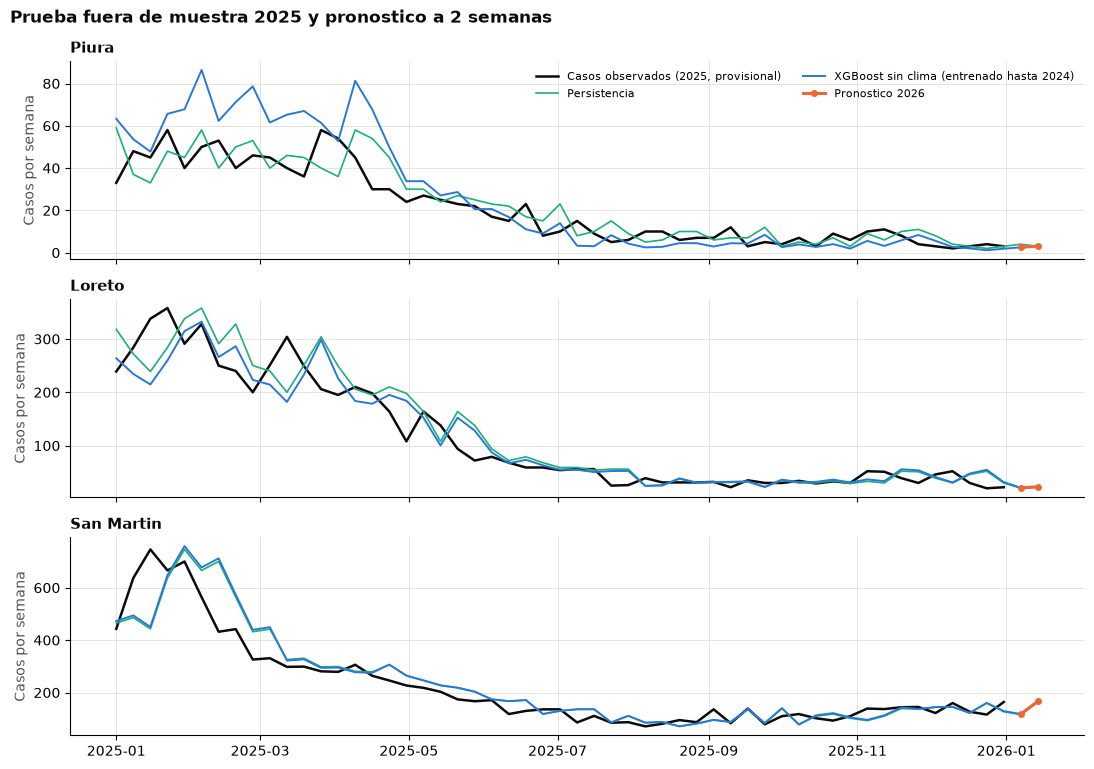

In [6]:
fig, ejes = plt.subplots(len(REGIONES), 1, figsize=(11, 2.6 * len(REGIONES)), sharex=True)
for ax, depto in zip(ejes, REGIONES):
    g = pred_2025[(pred_2025["departamento"] == depto) & (pred_2025["horizonte"] == 2)]
    ax.plot(g["fecha"], g["casos"], color=TINTA, lw=1.8, label="Casos observados (2025, provisional)")
    ax.plot(g["fecha"], g["Persistencia"], color=AQUA, lw=1.2, label="Persistencia")
    ax.plot(g["fecha"], g[SIN_CLIMA], color=AZUL, lw=1.4, label="XGBoost sin clima (entrenado hasta 2024)")
    futuro = g[g["casos"].isna()]
    ax.plot(futuro["fecha"], futuro[SIN_CLIMA], color=NARANJA, lw=2.2, marker="o", ms=4, label="Pronostico 2026")
    ax.set_title(depto.title(), loc="left", fontsize=11, fontweight="bold", color=TINTA)
    ax.set_ylabel("Casos por semana", color=TINTA_2)
    estilo(ax)
ejes[0].legend(loc="upper right", frameon=False, fontsize=8, ncol=2)
fig.suptitle("Prueba fuera de muestra 2025 y pronostico a 2 semanas", x=0.01, ha="left", fontsize=12,
             fontweight="bold", color=TINTA)
fig.tight_layout()
fig.savefig(OUT / "fuera_de_muestra_2025.png", dpi=120)
plt.show()

## 3. Pronóstico para las semanas siguientes al último dato

Cada horizonte *h* pronostica la semana *h* después del último dato. El umbral de brote (canal endémico) de 2026 usa los 7 años previos no epidémicos (2016, 2018–2022 y 2025).

In [7]:
casos_hist = pd.read_parquet(INTERIM / "casos_depto_semana.parquet")
umbrales = umbral_brote(pd.concat([casos_hist, casos_2025], ignore_index=True), hasta_ano=futuras[-1].year)
futuro = pred_2025[pred_2025["casos"].isna()].copy()
# cada horizonte pronostica su propia semana: h = 1 -> 1.a semana futura, ...
orden = {(a, s): i + 1 for i, (a, s) in enumerate(calendario[-max(HORIZONTES):])}
futuro = futuro[[orden[(a, s)] == h for a, s, h in zip(futuro["ano"], futuro["semana"], futuro["horizonte"])]]
futuro = marcar_brotes(futuro.rename(columns={SIN_CLIMA: "prediccion"}).assign(casos=lambda x: x["prediccion"]),
                       umbrales).rename(columns={"brote": "alerta"}).drop(columns="casos")
futuro["razon_umbral"] = futuro["prediccion"] / futuro["umbral"]
pronostico = futuro[["departamento", "ano", "semana", "fecha", "horizonte", "prediccion", "umbral", "razon_umbral", "alerta"]]
pronostico.to_csv(OUT / "pronostico_proximas_semanas.csv", index=False, float_format="%.1f")
print(pronostico.sort_values(["horizonte", "razon_umbral"], ascending=[True, False])
      .pivot_table(index="departamento", columns="horizonte", values="prediccion").round(0)
      .sort_values(1, ascending=False).to_string())
print("\nDepartamentos con alerta (pronostico sobre el canal endemico):",
      pronostico[pronostico["alerta"]].groupby("horizonte")["departamento"].apply(list).to_dict())

horizonte          1      2      3      4
departamento                             
SAN MARTIN     165.0  167.0  167.0  171.0
UCAYALI         57.0   53.0   56.0   53.0
AMAZONAS        30.0   30.0   30.0   30.0
LORETO          27.0   23.0   25.0   26.0
JUNIN           16.0   19.0   22.0   25.0
MADRE DE DIOS    8.0    9.0   10.0   10.0
CUSCO            7.0    7.0    7.0    8.0
HUANUCO          7.0    8.0    8.0    8.0
PASCO            7.0    6.0    6.0    6.0
CAJAMARCA        5.0    5.0    6.0    7.0
TUMBES           5.0    6.0    5.0    7.0
PIURA            2.0    3.0    3.0    5.0
AYACUCHO         2.0    2.0    2.0    2.0
LAMBAYEQUE       1.0    1.0    2.0    4.0
LA LIBERTAD      0.0    0.0    1.0    1.0
ANCASH           0.0    0.0    0.0    0.0
ICA              0.0    0.0    0.0    0.0

Departamentos con alerta (pronostico sobre el canal endemico): {1: ['SAN MARTIN'], 2: ['SAN MARTIN'], 3: ['SAN MARTIN'], 4: ['SAN MARTIN']}


## 4. Datos para el tablero

Un solo archivo con todo lo que muestra `app/tablero.py`:
- **2016–2024:** predicciones de la validación con origen móvil (notebook 11), de los cuatro modelos.
- **2025:** prueba fuera de muestra (XGBoost sin clima y persistencia).
- **2026, semanas 1 a 4:** pronóstico.

Cada fila tiene el umbral de brote, si fue brote y si hubo alerta.

In [8]:
rolling = pd.read_parquet(PROC / "predicciones_validacion_temporal.parquet")
rolling = rolling[["departamento", "ano", "semana", "fecha", "horizonte", "modelo", "casos", "prediccion"]]
oos = pred_2025[pred_2025["ano"] == 2025].melt(
    id_vars=["departamento", "ano", "semana", "fecha", "horizonte", "casos"],
    value_vars=[SIN_CLIMA, "Persistencia"], var_name="modelo", value_name="prediccion")
fut = pronostico.assign(modelo=SIN_CLIMA, casos=np.nan)[["departamento", "ano", "semana", "fecha", "horizonte",
                                                          "modelo", "casos", "prediccion"]]
tablero = pd.concat([rolling, oos, fut], ignore_index=True)
tablero = marcar_brotes(tablero, umbrales)   # agrega umbral y brote (False si no hay casos observados)
tablero["alerta"] = (tablero["prediccion"] > tablero["umbral"]) & (tablero["prediccion"] >= 5)
tablero["tipo"] = np.select([tablero["ano"] <= 2024, tablero["ano"] == 2025], ["Validacion 2016-2024", "Fuera de muestra 2025"],
                            "Pronostico")
assert tablero["umbral"].notna().all()
tablero.to_parquet(PROC / "tablero.parquet", index=False)
print(f"tablero.parquet: {len(tablero):,} filas, {tablero['departamento'].nunique()} departamentos, "
      f"{(PROC / 'tablero.parquet').stat().st_size / 1e6:.1f} MB")
print(tablero.groupby(["tipo", "modelo"]).size().to_string())

tablero.parquet: 134,844 filas, 17 departamentos, 1.1 MB
tipo                   modelo               
Fuera de muestra 2025  Persistencia              3604
                       XGBoost sin clima         3604
Pronostico             XGBoost sin clima           68
Validacion 2016-2024   Persistencia             31892
                       Regresion con rezagos    31892
                       XGBoost con clima        31892
                       XGBoost sin clima        31892


## Resultados y conclusiones

**Modelos guardados:** 136, es decir, 17 departamentos × 4 horizontes × 2 variantes (sin y con clima). Están en `modelos/`, junto con `metadatos.json`, que indica qué variables usa cada uno, su configuración y sus años de entrenamiento. Se regeneran ejecutando este notebook en unos 2 minutos.

**Prueba fuera de muestra 2025.** Es la prueba más honesta del proyecto: los modelos se entrenaron hasta 2024 y 2025 nunca se usó. Fue un año de pocos casos (34 105 en los 17 departamentos, frente a 177 678 en 2024).

| Anticipación | Departamentos donde el XGBoost sin clima tiene menos error que la persistencia | Mejora mediana del error |
|---|---|---|
| 1 semana | 13 de 17 | +3,4 % |
| 2 semanas | 12 de 17 | +3,5 % |
| 3 semanas | 13 de 17 | +3,2 % |
| 4 semanas | 11 de 17 | +2,9 % |

- **En Loreto y San Martín** el modelo iguala o mejora a la persistencia (Loreto: R² 0,83 frente a 0,74 a 4 semanas).
- **En Piura, en cambio, falla a 3–4 semanas** (R² −1,1). El modelo esperaba la subida de verano que aprendió de los años epidémicos (2017, 2023, 2024), y en 2025 no llegó: sobreestima entre 20 y 30 casos por semana. El error absoluto es pequeño, pero el R² sale muy negativo porque 2025 varió poco. **Es el riesgo de entrenar con años epidémicos:** el modelo tiende a anunciar subidas que no siempre ocurren.

**Pronóstico de las semanas 1 a 4 de 2026** (`outputs/pronostico_proximas_semanas.csv`):
- **San Martín** es el único departamento cuyo pronóstico supera el canal endémico, con unos 165–171 casos por semana.
- Le siguen Ucayali (unos 55), Amazonas (30) y Loreto (25), todos por debajo de su umbral.

**Datos del tablero:** `data/processed/tablero.parquet` (1,1 MB) junta la validación 2016–2024, la prueba 2025 y el pronóstico de 2026, con el umbral, los brotes y las alertas.
